# Import Manifest v2

In [4]:
import pandas as pd
from pathlib import Path

# Path to the manifest file
csv_path = Path(
    "/home/lawrence/Documents/School/thesis/PFAS_project_preprocessing_pipeline/"
    "manifest/100766_homo_sapiens_s1500_2.0_full_manifest_revB_2024.csv"
)

# Load the CSV
df = pd.read_csv(csv_path)[["GENE_SYMBOL", "PROBE_NAME", "PROBE_SEQUENCE"]]

# Preview the data
display(df.head())
df.info()

,GENE_SYMBOL,PROBE_NAME,PROBE_SEQUENCE
0,A2M,A2M_1,GAACAGGACTCCAGCAAAGCACTTTTCAGCCTTGTGGTCTTCAAGC...
1,AARS1,AARS1_3,TGCAGACACATCCTTGCCACCACCTTTACCGTCCATCAAGCCTGAC...
2,AATF,AATF_4,TAAGGACATGAAACCGAAGTTTCCTGCCTTTGCTGGCTTTCCTATC...
3,ABCB1,ABCB1_12,AAAGAGTTTCTGTATGGTACCTGCAAACTCTGAGCATACATATGTT...
4,ABCC2,ABCC2_22,CAGTTCTTCAGGGCTGCCGCACTCTATAATCTTCCCGTTGTCTAGG...


<class 'pandas.DataFrame'>
RangeIndex: 3386 entries, 0 to 3385
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   GENE_SYMBOL     3386 non-null   str  
 1   PROBE_NAME      3386 non-null   str  
 2   PROBE_SEQUENCE  3386 non-null   str  
dtypes: str(3)
memory usage: 79.5 KB


Confirm that all probes in the manifest are 50

count    3386.0
mean       50.0
std         0.0
min        50.0
25%        50.0
50%        50.0
75%        50.0
max        50.0
Name: PROBE_SEQUENCE_LENGTH, dtype: float64

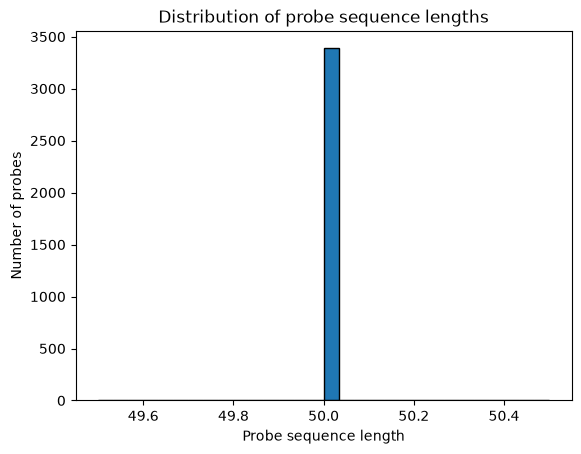

In [5]:
import matplotlib.pyplot as plt

# Count each probe sequence length
df["PROBE_SEQUENCE_LENGTH"] = df["PROBE_SEQUENCE"].str.len()

# View length summary
display(df["PROBE_SEQUENCE_LENGTH"].describe())

# Plot the distribution
df["PROBE_SEQUENCE_LENGTH"].plot.hist(bins=30, edgecolor="black")
plt.xlabel("Probe sequence length")
plt.ylabel("Number of probes")
plt.title("Distribution of probe sequence lengths")
plt.show()

,count,mean,std,min,25%,50%,75%,max
PROBE_GC_CONTENT,3386.0,49.936208,7.890428,22.0,44.0,50.0,54.0,86.0


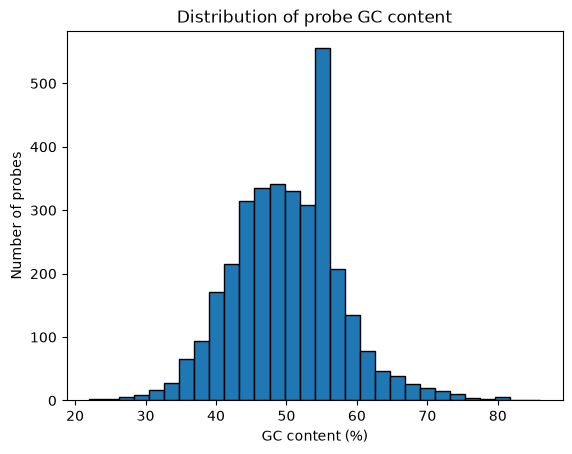

In [6]:
import matplotlib.pyplot as plt

# Calculate GC content as a percentage
gc_count = df["PROBE_SEQUENCE"].str.upper().str.count("[GC]")
sequence_length = df["PROBE_SEQUENCE"].str.len()

df["PROBE_GC_CONTENT"] = (
    gc_count.div(sequence_length.where(sequence_length > 0)) * 100
)

# Summary statistics
gc_summary = df["PROBE_GC_CONTENT"].describe().to_frame().T
display(gc_summary)

# Plot the distribution
df["PROBE_GC_CONTENT"].plot.hist(bins=30, edgecolor="black")
plt.xlabel("GC content (%)")
plt.ylabel("Number of probes")
plt.title("Distribution of probe GC content")
plt.show()